<a href="https://colab.research.google.com/github/shailshree23/ML2_Lab/blob/main/SHAP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install shap

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

In [3]:
wine = load_wine()

X = pd.DataFrame(wine.data, columns=wine.feature_names)

# Convert into a binary classification problem
y = (wine.target == 0).astype(int)

print("Dataset:")
display(X.head())

print("Total samples:", len(X))

Dataset:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


Total samples: 178


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 142
Testing samples: 36


In [5]:
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

# Predict test data
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Model trained successfully!")
print("Accuracy:", round(accuracy * 100, 2), "%")

Model trained successfully!
Accuracy: 100.0 %


In [6]:
# Create SHAP explainer
explainer = shap.TreeExplainer(model)

# Explain first two test instances
shap_values = explainer(X_test.iloc[:2])

print("SHAP values calculated successfully!")

SHAP values calculated successfully!


,Feature,Importance
6,flavanoids,0.180810
12,proline,0.118586
5,total_phenols,0.077259
0,alcohol,0.071128
3,alcalinity_of_ash,0.054949
9,color_intensity,0.041263
11,od280/od315_of_diluted_wines,0.030229
4,magnesium,0.026672
8,proanthocyanins,0.010198
10,hue,0.009408


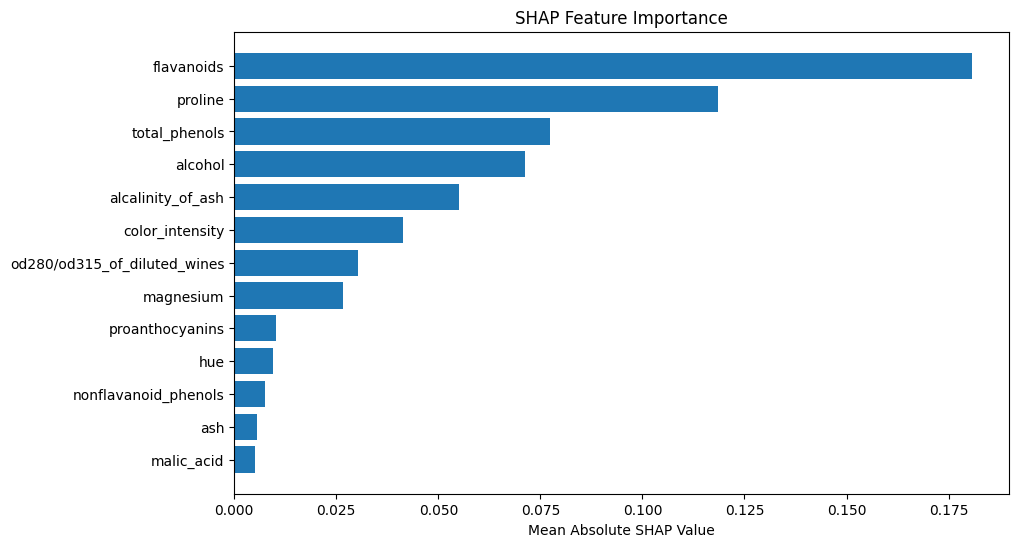

In [7]:
# Extract SHAP values for class 1
values = shap_values.values

if values.ndim == 3:
    values = values[:, :, 1]

# Calculate average importance
importance = np.abs(values).mean(axis=0)

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importance
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

display(feature_importance)

# Plot feature importance
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance['Feature'],
    feature_importance['Importance']
)

plt.xlabel("Mean Absolute SHAP Value")
plt.title("SHAP Feature Importance")
plt.gca().invert_yaxis()
plt.show()

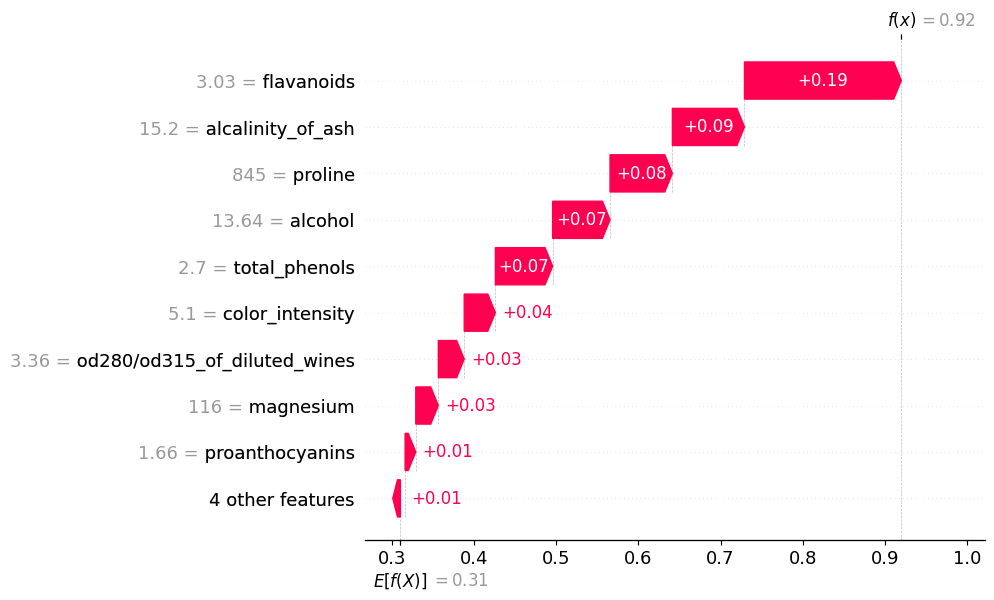

In [8]:
if shap_values.values.ndim == 3:
    shap.plots.waterfall(shap_values[0, :, 1])
else:
    shap.plots.waterfall(shap_values[0])

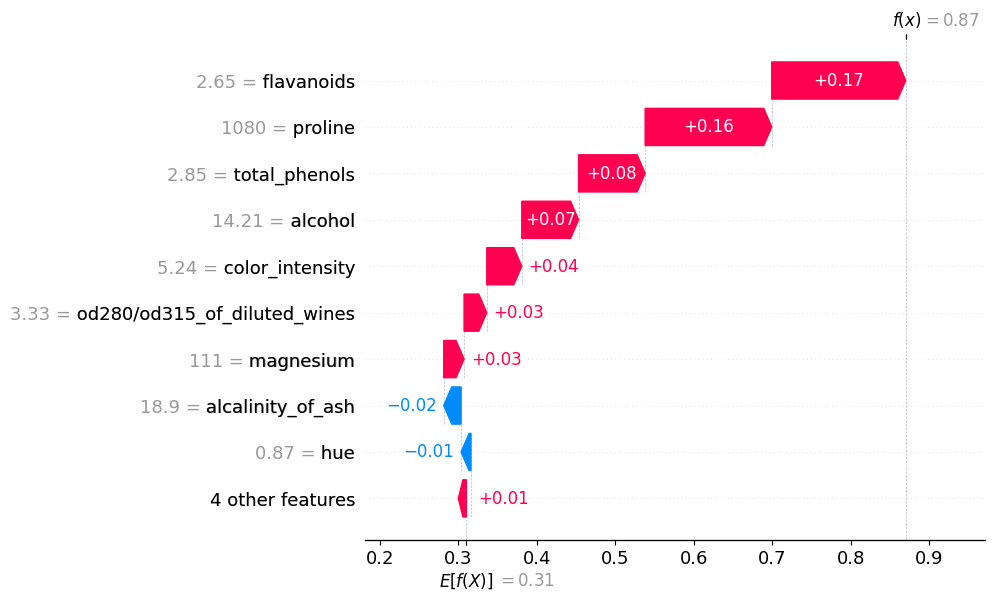

In [9]:
if shap_values.values.ndim == 3:
    shap.plots.waterfall(shap_values[1, :, 1])
else:
    shap.plots.waterfall(shap_values[1])